## OSRM Network Query

Key files needed: 

| File | Used for |
|---|---|
| output/hdb_blocks.gpkg | Residential points - my origins | 
| data/ChildCareServices_2021.geojson| Residential points - my destinations| 
| data/MasterPlanSubZones_2019.geojson | Study area |

Key Dependencies:

| Library | Purpose |
|---|---|
| `xlogit` | Model estimation |
| `pandas` | Tabular data manipulation |
| `matplotlib` | QA scatter plots |
| `pickle` | Save and export models |
| `numpy` | Data processing |
| `statsmodels` | |
| `seaborn` | Graphs for checking correlation between model variables|
| `folium` | Visualisation of routes|


The extracted OSRM Singapore files can also be directly downloaded here. 
Data for running OSRM via Docker:
https://www.dropbox.com/scl/fo/de4tvoq346ylpexiz2k2s/AAKRUqoSCLjPv95NMsHSMMM?rlkey=sddbtns26x7skqf0d8nh98yak&st=3ytafdb2&dl=0

But, if you prefer to extract the data yourself, please follow the manual extraction instructions:


--- 

### Manual Extraction

1. First, please obtain the OSRM files through running osrm-extract in Docker on the singapore_only osm.pbf file in your Shell/Terminal:

OSRM uses Lua profiles (such as car.lua, bicycle.lua, or foot.lua) to determine which roads are passable for a specific transport mode. Use the osrm-extract tool to parse the PBF data.

```bash
docker run -t -v "${PWD}:/data" osrm/osrm-backend osrm-extract -p /opt/car.lua /data/singapore.osm.pbf
```

(Replace with *walk* for the walking profiles)

2. Next, prepare the data for the Multi-Level Dijkstra (MLD) routing algorithm. This requires partitioning the map into cells and calculating routing weights.

#### Partition the graph into cells
```bash
docker run -t -v "${PWD}:/data" osrm/osrm-backend osrm-partition /data/singapore-latest.osrm`
```

#### Customize the cells with routing weights
```bash
docker run -t -v "${PWD}:/data" osrm/osrm-backend osrm-customize /data/singapore-latest.osrm`
```

### Local OSRM routing servers

Accessibility costs (\(C_{i,j}^{m}\)) are computed via local OSRM instances, one per mode. Each assumes the corresponding `.osrm` graph has already been built (`osrm-extract` → `osrm-partition` → `osrm-customize`) into the mounted data folder.

| Mode    | Port | Data folder       |
|---------|------|--------------------|
| Walking | 5001 | `OSRMData_Walk`    |
| Driving | 5002 | `OSRMData_Drive`   |



```bash
# Walking — port 5001
docker run --volume="<your_path>/OSRMData_Walk:/data" -p 5001:5000 -d osrm/osrm-backend
```

```bash
# Driving — port 5002
docker run --volume="<your_path>/OSRMData_Drive:/data" -p 5002:5000 -d osrm/osrm-backend
\`\`\`

# ─────────────────────────────────────────────

### Notes for BT4015 Analysis
How to calculate timings between each origin + destination?
###
Neighbourhood - its closest childcare centre 

In [1]:
#origin - destination matrix

import requests
import numpy as np
import pandas as pd
import geopandas as gpd

def get_osrm_matrix(origins, destinations, mode="foot", metric="duration"):
    """Return an OSRM matrix: duration in minutes or distance in metres."""
    if metric not in ("duration", "distance"):
        raise ValueError("metric must be 'duration' or 'distance'")

    coords = origins + destinations
    coords_str = ";".join(f"{lon},{lat}" for lon, lat in coords)

    url = f"http://localhost:5002/table/v1/{mode}/{coords_str}"
    params = {
        "sources": ";".join(map(str, range(len(origins)))),
        "destinations": ";".join(map(str, range(len(origins), len(coords)))),
        "annotations": metric,
    }

    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    data = response.json()

    if data.get("code") != "Ok":
        raise RuntimeError(f"OSRM error: {data.get('message', data)}")

    key = "durations" if metric == "duration" else "distances"
    matrix = np.array(
        [
            [value if value is not None else np.inf for value in row]
            for row in data[key]
        ],
        dtype=float,
    )

    return matrix / 60 if metric == "duration" else matrix


def chunk_list(coords, chunk_size):
    """Yield coordinate batches of at most chunk_size."""
    for start in range(0, len(coords), chunk_size):
        yield coords[start:start + chunk_size]

### Calculating timings for walk matrix

Matrix jsons are saved in a .gitignore folder /large_data - file sizes should be around ~150 and ~200 mb respectively

In [2]:
#files

hdbs = gpd.read_file("../large_data/hdb_points_TEST.geojson")
ccs = gpd.read_file("../data/ChildCareServices_2021.geojson")

print(f"Loaded {len(hdbs)} HDB points and {len(ccs)} childcare services.")

Loaded 10741 HDB points and 1925 childcare services.


In [3]:
from tqdm.auto import tqdm

gdf_origins = hdbs.copy()
gdf_destinations = ccs.copy()

gdf_origins = gdf_origins.to_crs(epsg=4326) #wgs84, osrm only works in global coordinates
gdf_destinations = gdf_destinations.to_crs(epsg=4326)

# OSRM coordinate order: (longitude, latitude)
coords_origins = list(zip(
    gdf_origins.geometry.x,
    gdf_origins.geometry.y
))
coords_destinations = list(zip(
    gdf_destinations.geometry.x,
    gdf_destinations.geometry.y
))

print(coords_origins[:3])
#should be around (103, 1.3)


#maximum chunk size for OSRM requests
max_size = 100

# crear una matriz completa llena de infinitos, de tamaño (num_origenes x num_destinos)
matrix_time = np.full((len(coords_origins), len(coords_destinations)), np.inf)
matrix_dist = np.full((len(coords_origins), len(coords_destinations)), np.inf)

# dividir orígenes y destinos en sub-listas
origen_chunks = list(chunk_list(coords_origins, max_size))
destino_chunks = list(chunk_list(coords_destinations, max_size))

num_origins = len(coords_origins)
num_destinations = len(coords_destinations)
total_queries = 2 * len(origen_chunks) * len(destino_chunks)
print(f"Origins: {num_origins:,} | Destinations: {num_destinations:,}")
print(f"Origin-destination pairs: {num_origins * num_destinations:,} | OSRM queries: {total_queries:,}")

# Each batch makes two requests: duration and distance.
with tqdm(total=total_queries, desc="OSRM queries", unit="query") as progress:
    for i, sub_origins in enumerate(origen_chunks):
        for j, sub_destinations in enumerate(destino_chunks):
            ini_i = i * max_size
            fin_i = ini_i + len(sub_origins)
            ini_j = j * max_size
            fin_j = ini_j + len(sub_destinations)
            progress.set_postfix_str(
                f"origins {ini_i + 1:,}-{fin_i:,}/{num_origins:,}, "
                f"destinations {ini_j + 1:,}-{fin_j:,}/{num_destinations:,}"
            )

            sub_matriz_t = get_osrm_matrix(sub_origins, sub_destinations, mode='foot', metric='duration')
            matrix_time[ini_i:fin_i, ini_j:fin_j] = sub_matriz_t
            progress.update(1)

            sub_matriz_d = get_osrm_matrix(sub_origins, sub_destinations, mode='foot', metric='distance')
            matrix_dist[ini_i:fin_i, ini_j:fin_j] = sub_matriz_d
            progress.update(1)

# convertir la matriz (numpy array) en un DataFrame de pandas, con index de orígenes y columns de destinos
walk_matrix_time = pd.DataFrame(matrix_time, index=gdf_origins.index, columns=gdf_destinations.index)
walk_matrix_dist = pd.DataFrame(matrix_dist, index=gdf_origins.index, columns=gdf_destinations.index)

# export matrix to json for use 
walk_matrix_time.to_json("../large_data/walk_matrix_time.json", orient="split")
walk_matrix_dist.to_json("../large_data/walk_matrix_dist.json", orient="split")

/opt/anaconda3/envs/h3_env_312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[(103.74684200757073, 1.3413230558229585), (103.76036105079291, 1.3856340613434799), (103.79346353096793, 1.307620048585763)]
Origins: 10,741 | Destinations: 1,925
Origin-destination pairs: 20,676,425 | OSRM queries: 4,320


OSRM queries: 100%|██████████| 4320/4320 [12:20<00:00,  5.83query/s, origins 10,701-10,741/10,741, destinations 1,901-1,925/1,925]


# ─────────────────────────────────────────────

## Route Visualisation - Folium
Visualising shortest paths from each hdb centroid to each childhood centre

In [4]:
# Map a reproducible sample of HDBs and their nearest childcare by walking time.
import folium
from folium.plugins import MarkerCluster
from html import escape
from tqdm.auto import tqdm

MAX_ORIGINS = 100  # Set to None to show every origin (many route requests).
OSRM_WALK_URL = "http://localhost:5002"

if not coords_origins or not coords_destinations:
    raise ValueError("Run the matrix cell first with non-empty origins and destinations.")
if (walk_matrix_time.shape != (len(coords_origins), len(coords_destinations))
        or not walk_matrix_time.index.equals(gdf_origins.index)
        or not walk_matrix_time.columns.equals(gdf_destinations.index)):
    raise ValueError("The walking matrix does not match the current points. Rerun the matrix cell.")

origin_positions = np.arange(len(coords_origins))
if MAX_ORIGINS is not None and len(origin_positions) > MAX_ORIGINS:
    origin_positions = np.sort(np.random.default_rng(42).choice(
        origin_positions, size=MAX_ORIGINS, replace=False
    ))

# OSRM coordinates are (longitude, latitude); Folium uses (latitude, longitude).
map_center = [np.mean([lat for lon, lat in coords_origins]),
              np.mean([lon for lon, lat in coords_origins])]
m = folium.Map(location=map_center, zoom_start=12, tiles="OpenStreetMap")
origin_layer = MarkerCluster(name="HDB origins (displayed sample)").add_to(m)
destination_layer = MarkerCluster(name="Childcare centres (all)").add_to(m)
route_layer = folium.FeatureGroup(name="Routes to nearest childcare by time").add_to(m)

for j, (lon, lat) in enumerate(coords_destinations):
    label = escape(str(gdf_destinations.index[j]))
    folium.Marker(
        [lat, lon], popup=f"Childcare index: {label}",
        icon=folium.Icon(color="green", icon="info-sign")
    ).add_to(destination_layer)

print(f"Displaying {len(origin_positions):,}/{len(coords_origins):,} HDB origins "
      f"and {len(coords_destinations):,} childcare destinations.")
routes_drawn = 0
no_finite_time = 0
route_errors = []
with requests.Session() as session:
    for i in tqdm(origin_positions, desc="Loading walking routes", unit="origin"):
        origin = coords_origins[i]
        origin_label = escape(str(gdf_origins.index[i]))
        times = walk_matrix_time.iloc[i].to_numpy(dtype=float)
        finite_positions = np.flatnonzero(np.isfinite(times))
        popup = f"HDB index: {origin_label}"
        if len(finite_positions):
            j = int(finite_positions[np.argmin(times[finite_positions])])
            destination_label = escape(str(gdf_destinations.index[j]))
            popup += (f"<br>Nearest childcare index: {destination_label}"
                      f"<br>Matrix walking time: {times[j]:.1f} min")
            destination = coords_destinations[j]
            coordinates = f"{origin[0]},{origin[1]};{destination[0]},{destination[1]}"
            try:
                response = session.get(
                    f"{OSRM_WALK_URL}/route/v1/foot/{coordinates}",
                    params={"overview": "full", "geometries": "geojson"},
                    timeout=30,
                )
                response.raise_for_status()
                data = response.json()
                if data.get("code") != "Ok" or not data.get("routes"):
                    raise ValueError(data.get("message", data.get("code", "No route returned")))
                route = data["routes"][0]
                route_popup = (popup + f"<br>Route distance: {route['distance'] / 1000:.2f} km"
                               f"<br>Route time: {route['duration'] / 60:.1f} min")
                folium.PolyLine(
                    [(lat, lon) for lon, lat in route["geometry"]["coordinates"]],
                    color="blue", weight=3, opacity=0.65,
                    tooltip=f"HDB {origin_label} → childcare {destination_label}",
                    popup=route_popup,
                ).add_to(route_layer)
                routes_drawn += 1
            except (requests.RequestException, ValueError, KeyError, IndexError) as exc:
                route_errors.append(f"HDB {gdf_origins.index[i]}: {exc}")
                popup += "<br>Route geometry unavailable"
        else:
            no_finite_time += 1
            popup += "<br>No finite travel times in matrix (unreachable or failed query)"

        folium.Marker(
            [origin[1], origin[0]], popup=popup,
            icon=folium.Icon(color="blue", icon="home")
        ).add_to(origin_layer)

folium.LayerControl().add_to(m)
m.save("routes_map.html")
print(f"Saved routes_map.html: {routes_drawn:,} routes; "
      f"{no_finite_time:,} origins without finite times; {len(route_errors):,} route errors.")
for error in route_errors[:5]:
    print(error)

m


Displaying 100/10,741 HDB origins and 1,925 childcare destinations.


Loading walking routes: 100%|██████████| 100/100 [00:00<00:00, 280.81origin/s]


Saved routes_map.html: 100 routes; 0 origins without finite times; 0 route errors.


### Creating accessibility map: which areas are the most well-connected to childcare centres?


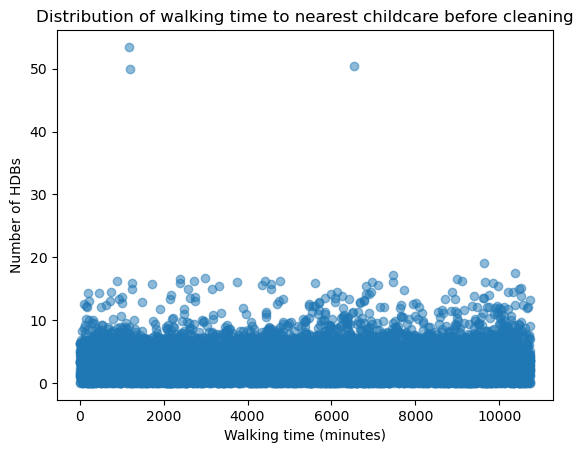

count    10738.000000
mean         3.407415
std          2.335592
min          0.000000
25%          1.800000
50%          3.090833
75%          4.613333
max         19.038333
Name: nearest_cc_minutes, dtype: float64


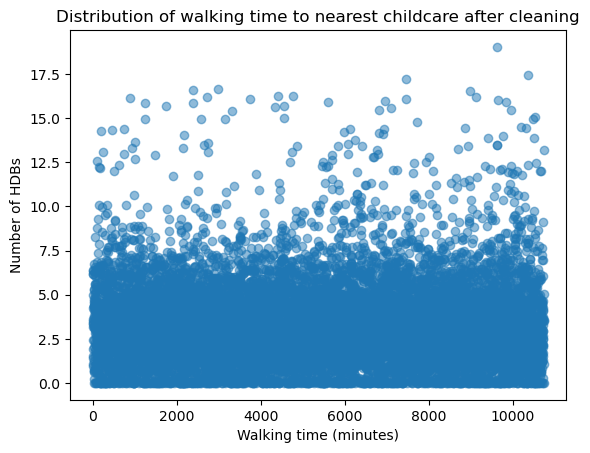

In [5]:
## First clean output of the matrix in case theres inf values.
# Treat unreachable routes as missing values
times = walk_matrix_time.replace([np.inf, -np.inf], np.nan)

import matplotlib.pyplot as plt

# Minimum walking time across all CCs for each HDB
hdb_access = hdbs.copy()
hdb_access["nearest_cc_minutes"] = times.min(axis=1).reindex(hdb_access.index)

plt.scatter(x=hdb_access.index, y=hdb_access["nearest_cc_minutes"], alpha=0.5)
plt.title("Distribution of walking time to nearest childcare before cleaning")
plt.xlabel("Walking time (minutes)")
plt.ylabel("Number of HDBs")

plt.show()

#remove outliers > 40
hdb_access = hdb_access[hdb_access["nearest_cc_minutes"] <= 40]

print(hdb_access["nearest_cc_minutes"].describe())

plt.scatter(x=hdb_access.index, y=hdb_access["nearest_cc_minutes"], alpha=0.5)
plt.title("Distribution of walking time to nearest childcare after cleaning")
plt.xlabel("Walking time (minutes)")
plt.ylabel("Number of HDBs")

plt.show()

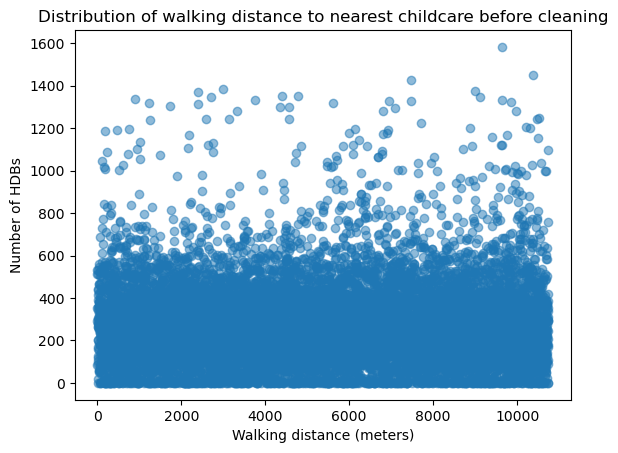

count    10735.000000
mean       283.311821
std        194.033555
min          0.000000
25%        149.700000
50%        257.100000
75%        383.500000
max       1583.000000
Name: nearest_cc_distance, dtype: float64


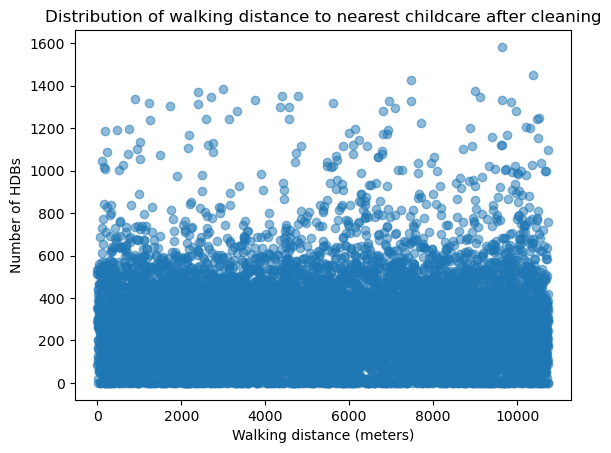

In [6]:
## cleaning of distance matrix

## First clean output of the matrix in case theres inf values.
# Treat unreachable routes as missing values
distances = walk_matrix_dist.replace([np.inf, -np.inf], np.nan)

import matplotlib.pyplot as plt

# Minimum walking time across all CCs for each HDB
hdb_access["nearest_cc_distance"] = distances.min(axis=1).reindex(hdb_access.index)

plt.scatter(x=hdb_access.index, y=hdb_access["nearest_cc_distance"], alpha=0.5)
plt.title("Distribution of walking distance to nearest childcare before cleaning")
plt.xlabel("Walking distance (meters)")
plt.ylabel("Number of HDBs")

plt.show()

#remove outliers > 3000
hdb_access = hdb_access[(hdb_access["nearest_cc_distance"] <= 3000) & (hdb_access["nearest_cc_distance"] >= 0)]

print(hdb_access["nearest_cc_distance"].describe())

plt.scatter(x=hdb_access.index, y=hdb_access["nearest_cc_distance"], alpha=0.5)
plt.title("Distribution of walking distance to nearest childcare after cleaning")
plt.xlabel("Walking distance (meters)")
plt.ylabel("Number of HDBs")

plt.show()

### Initial stats and what they tell us

The average walking time to a childcare centre from any given HDBs is around only 3 minutes - and most neighbourhoods (75%) are able to get to a centre in less than **5 minutes/400m**. Accessibility in Singapore to childcare facilities for HDBs is generally very good. However, we still need to look at the density of HDBs vs. density of childcare centres to understand the potential demand put on these centres. Only then will we be able to achieve a fuller picture of how easy it is for parents to get their children to a centre. 

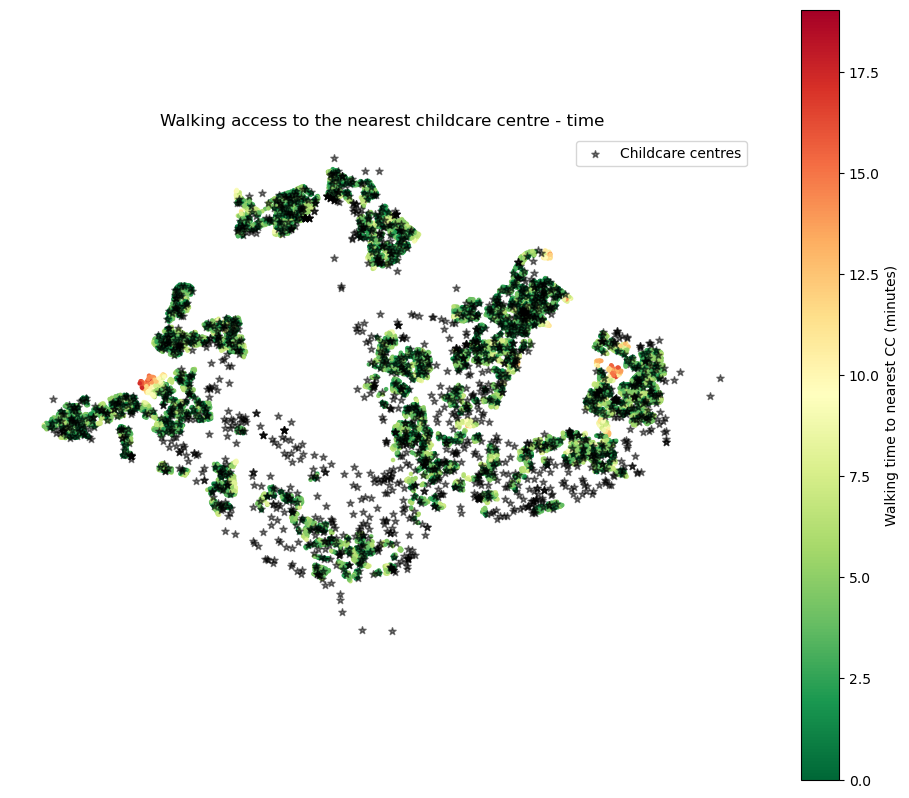

In [7]:
fig, ax = plt.subplots(figsize=(12, 10))

hdb_access.plot(
    column="nearest_cc_minutes",
    cmap="RdYlGn_r",  # green - red (better accessibility - worse accessibility)
    markersize=5,
    legend=True,
    legend_kwds={"label": "Walking time to nearest CC (minutes)"},
    missing_kwds={"color": "lightgrey", "label": "No reachable CC"},
    ax=ax,
)

ccs.to_crs(hdb_access.crs).plot(
    ax=ax,
    color="black",
    marker="*",
    markersize=30,
    alpha = 0.5,
    label="Childcare centres",
)

ax.set_title("Walking access to the nearest childcare centre - time")
ax.set_axis_off()
ax.legend()
plt.show()


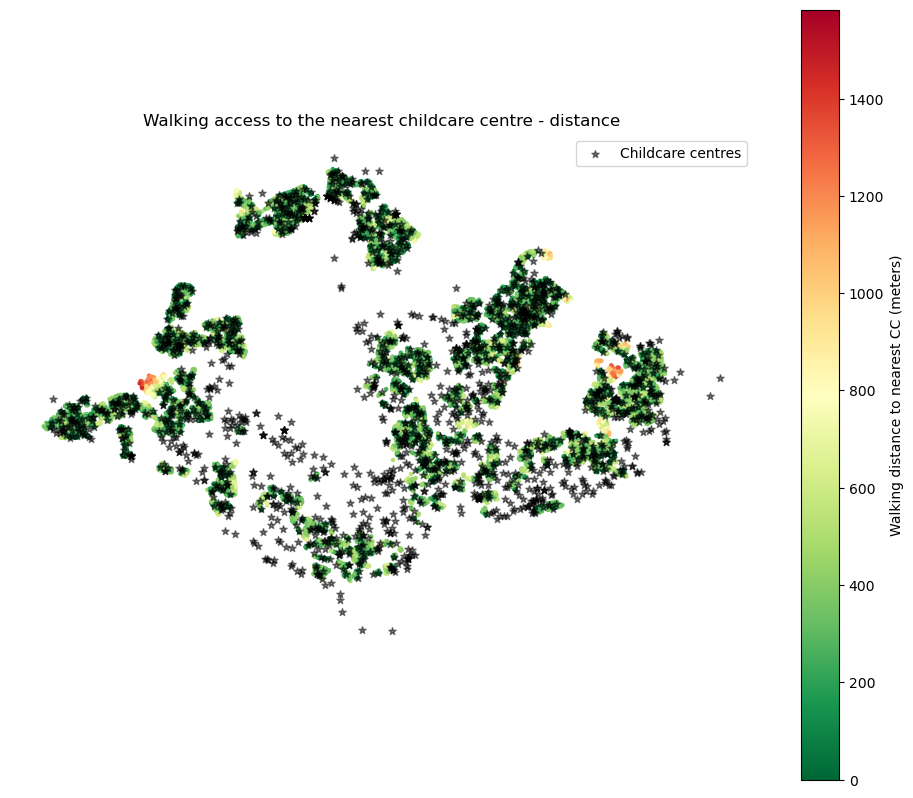

In [8]:
## in terms of distance (meters)
fig, ax = plt.subplots(figsize=(12, 10))

hdb_access.plot(
    column="nearest_cc_distance",
    cmap="RdYlGn_r",  # green - red (better accessibility - worse accessibility)
    markersize=5,
    legend=True,
    legend_kwds={"label": "Walking distance to nearest CC (meters)"},
    missing_kwds={"color": "lightgrey", "label": "No reachable CC"},
    ax=ax,
)

ccs.to_crs(hdb_access.crs).plot(
    ax=ax,
    color="black",
    marker="*",
    markersize=30,
    alpha = 0.5,
    label="Childcare centres",
)

ax.set_title("Walking access to the nearest childcare centre - distance")
ax.set_axis_off()
ax.legend()
plt.show()


### KDE density estimation — HDBs vs. childcare centres

Compare the spatial concentration of all loaded `hdbs` points and `ccs` points. Use the original HDB points rather than `hdb_access`, which excludes buildings based on walking accessibility. Each point has equal weight; this is not a measure of residents, childcare capacity, or walking accessibility.

Both maps use Singapore's boundary and the same extent. Each KDE is normalised and coloured independently, so compare hotspot locations rather than treating matching colours as equal numbers of buildings/centres per square kilometre. `bw_adjust` controls smoothing relative to each dataset's automatically selected bandwidth.


Reference: [Geoplot KDE documentation](https://residentmario.github.io/geoplot/plot_references/plot_reference.html)


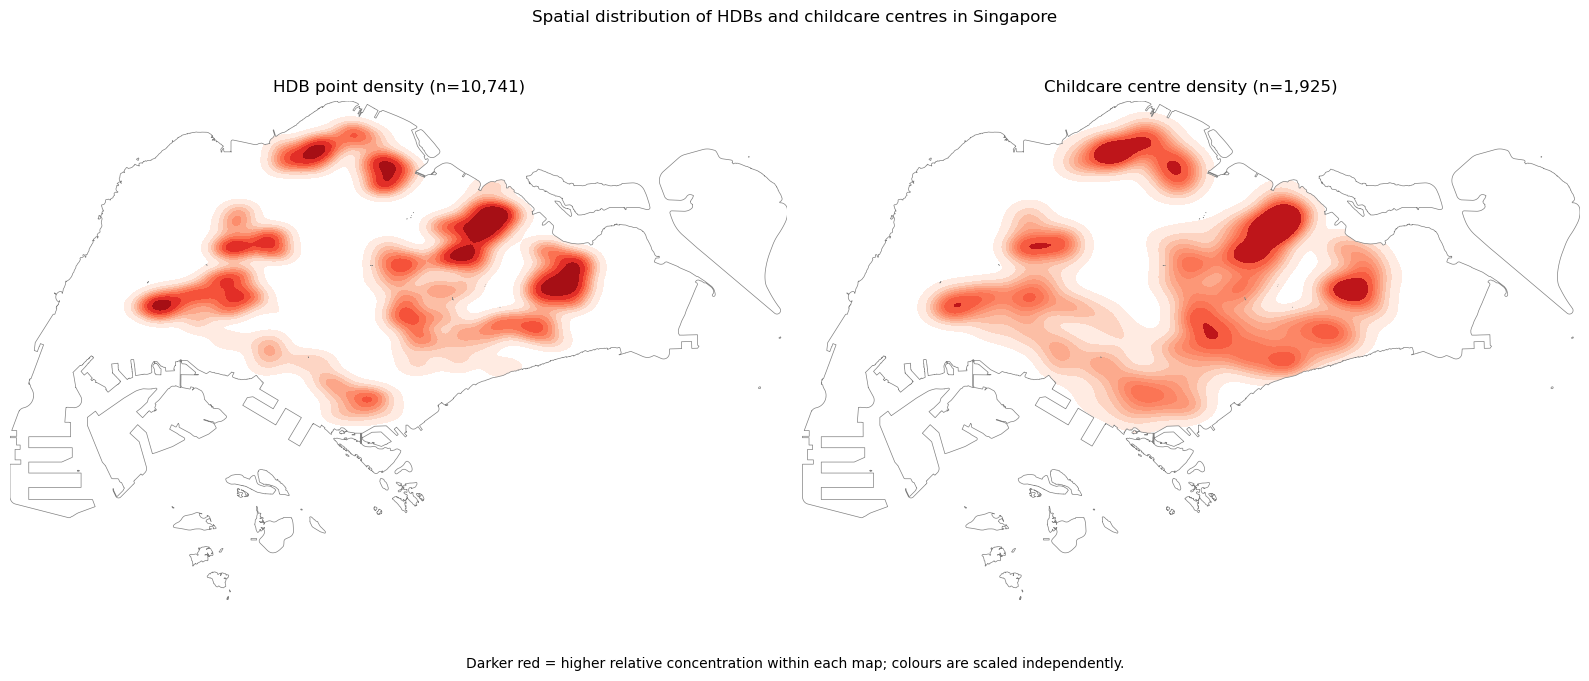

In [13]:
import geoplot as gplt
import cartopy.crs as ccrs
from cartopy.mpl.path import shapely_to_path
import geopandas as gpd
import matplotlib.pyplot as plt

hdb_points = hdbs.to_crs(epsg=4326)
cc_points = ccs.to_crs(epsg=4326)
subzones = gpd.read_file("../data/MasterPlanSubZones_2019.geojson")
singapore = subzones.to_crs(epsg=4326).dissolve()
extent = tuple(singapore.total_bounds)

proj = ccrs.AlbersEqualArea(
    central_latitude=1.35,
    central_longitude=103.82,
    standard_parallels=(1.0, 2.0),
)
fig, axes = plt.subplots(
    1, 2, figsize=(16, 7),
    subplot_kw={"projection": proj},
)

for ax, points, title in zip(
    axes,
    [hdb_points, cc_points],
    ["HDB point density", "Childcare centre density"],
):
    points = points.loc[
        points.geometry.notna()
        & ~points.geometry.is_empty
        & (points.geom_type == "Point")
    ]
    existing_collections = len(ax.collections)
    gplt.kdeplot(
        points,
        cmap="Reds",
        fill=True,
        thresh=0.05,
        bw_adjust=0.5,  # Increase for a smoother surface.
        extent=extent,
        ax=ax,
    )
    # Clip the KDE itself. Geoplot's white outside-mask can cover the
    # entire density layer with this Cartopy/Shapely combination.
    boundary_path = shapely_to_path(
        proj.project_geometry(singapore.geometry.iloc[0], ccrs.PlateCarree())
    )
    for collection in list(ax.collections)[existing_collections:]:
        collection.set_clip_path(boundary_path, ax.transData)

    gplt.polyplot(
        singapore, ax=ax, extent=extent,
        facecolor="none", edgecolor="grey", linewidth=0.5, zorder=2,
    )
    ax.set_title(f"{title} (n={len(points):,})")
    ax.set_axis_off()

fig.suptitle("Spatial distribution of HDBs and childcare centres in Singapore")
fig.text(
    0.5, 0.04,
    "Darker red = higher relative concentration within each map; "
    "colours are scaled independently.",
    ha="center", fontsize=10,
)
plt.tight_layout(rect=(0, 0.08, 1, 0.95))
plt.show()

### 5-, 10-, and 15-minute walking catchments

These maps show **HDB-point catchments**: whether an HDB can reach at least one childcare centre within each threshold, using the saved OSRM walking-time matrix (minutes, HDB → childcare direction). They are sampled accessibility maps, not continuous network isochrone polygons; we do not interpolate across unobserved land or draw circular distance buffers.

Use all original HDB points, before the 40-minute/3,000-metre accessibility filters. Thresholds are cumulative and inclusive (≤5, ≤10, ≤15 minutes). Each HDB point receives equal weight; coverage is not population-weighted and reachable-centre counts do not measure available childcare places.

Missing, infinite, or negative matrix values are treated as unknown. A known route within a threshold confirms coverage even if other routes are missing. An HDB is confirmed beyond a threshold only when all destination times are known. Otherwise, its coverage is unknown. Reachable-centre counts are lower bounds for rows with missing times.

Run the data-loading cell first. If `walk_matrix_time` is not in memory, this section loads the saved matrix without querying OSRM. The results assume the matrix was produced with the walking routing profile described above; matrix labels must match the loaded points.


In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

thresholds = (5, 10, 15)
if "walk_matrix_time" not in globals():
    walk_matrix_time = pd.read_json(
        Path("../large_data/walk_matrix_time.json"), orient="split"
    )

# Check both axes before associating matrix rows with locations.
if (not hdbs.index.is_unique or not ccs.index.is_unique
        or not walk_matrix_time.index.is_unique
        or not walk_matrix_time.columns.is_unique
        or len(hdbs) != len(walk_matrix_time.index)
        or len(ccs) != len(walk_matrix_time.columns)
        or not hdbs.index.isin(walk_matrix_time.index).all()
        or not ccs.index.isin(walk_matrix_time.columns).all()):
    raise ValueError("Walking matrix labels do not match hdbs/ccs. Load matching data.")
if len(hdbs) == 0 or len(ccs) == 0:
    raise ValueError("HDB and childcare datasets must both contain points.")

catchment_times = walk_matrix_time.reindex(index=hdbs.index, columns=ccs.index)
catchment_times = catchment_times.where(
    np.isfinite(catchment_times) & catchment_times.ge(0)
)
hdb_catchments = hdbs.copy()
hdb_catchments["nearest_cc_minutes"] = catchment_times.min(axis=1)
hdb_catchments["complete_times"] = catchment_times.notna().all(axis=1)
coverage_rows = []
for minutes in thresholds:
    counts = catchment_times.le(minutes).sum(axis=1)
    covered = counts.gt(0)
    beyond = ~covered & hdb_catchments["complete_times"]
    unknown = ~covered & ~hdb_catchments["complete_times"]
    hdb_catchments[f"ccs_within_{minutes}min"] = counts
    hdb_catchments[f"access_{minutes}min"] = np.select(
        [covered, beyond], ["Within threshold", "Beyond threshold"],
        default="Unknown",
    )
    coverage_rows.append({
        "Threshold (minutes)": minutes,
        "HDBs covered": int(covered.sum()),
        "Coverage (% of all HDBs)": round(100 * covered.mean(), 2),
        "HDBs confirmed beyond": int(beyond.sum()),
        "HDBs unknown": int(unknown.sum()),
        "Median known reachable CCs per HDB": float(counts.median()),
    })
catchment_summary = pd.DataFrame(coverage_rows).set_index("Threshold (minutes)")
display(catchment_summary)
print(f"Denominator: {len(hdb_catchments):,} HDB points. "
      f"{(~hdb_catchments['complete_times']).sum():,} HDBs have incomplete route times.")
print("Centre counts are lower bounds where route times are missing.")


,HDBs covered,Coverage (% of all HDBs),HDBs confirmed beyond,HDBs unknown,Median known reachable CCs per HDB
Threshold (minutes),,,,,
5,8591,79.98,0,2150,2.0
10,10564,98.35,0,177,8.0
15,10711,99.72,0,30,18.0


Denominator: 10,741 HDB points. 10,741 HDBs have incomplete route times.
Centre counts are lower bounds where route times are missing.


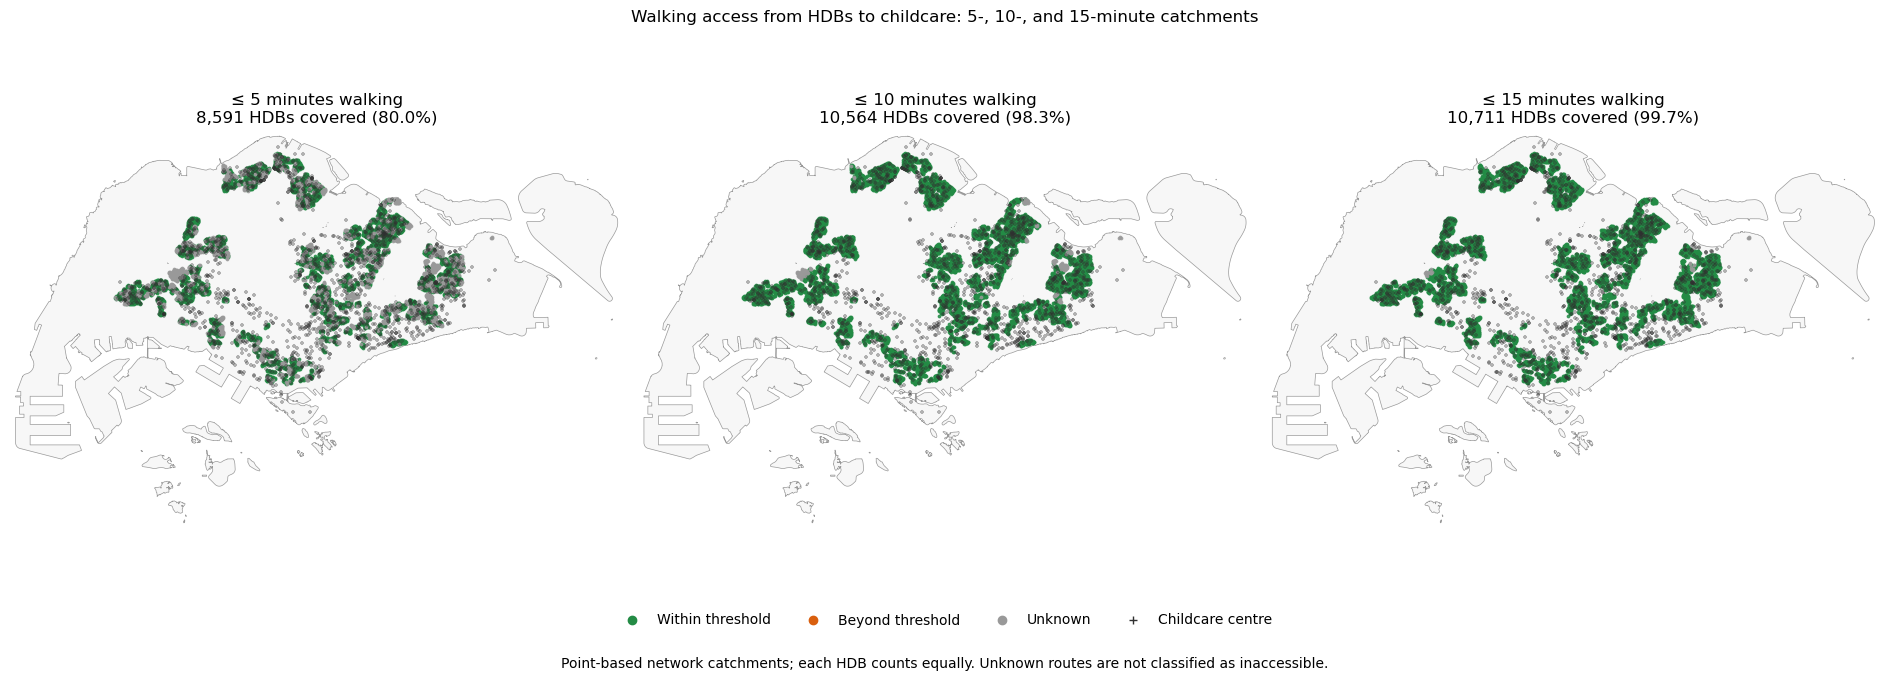

In [15]:
# Use Singapore's metric CRS for plotting; no KDE or interpolation is needed.
catchment_boundary = gpd.read_file(
    "../data/MasterPlanSubZones_2019.geojson"
).to_crs(epsg=3414).dissolve()
catchment_points = hdb_catchments.to_crs(epsg=3414)
catchment_centres = ccs.to_crs(epsg=3414)
xmin, ymin, xmax, ymax = catchment_boundary.total_bounds
padding = 500  # metres
colours = {
    "Within threshold": "#238b45",
    "Beyond threshold": "#d95f0e",
    "Unknown": "#999999",
}
fig, axes = plt.subplots(1, 3, figsize=(19, 7))
for ax, minutes in zip(axes, thresholds):
    catchment_boundary.plot(
        ax=ax, facecolor="#f7f7f7", edgecolor="#999999", linewidth=0.5,
    )
    for status in ["Within threshold", "Beyond threshold", "Unknown"]:
        subset = catchment_points.loc[
            catchment_points[f"access_{minutes}min"].eq(status)
        ]
        if not subset.empty:
            subset.plot(ax=ax, color=colours[status], markersize=3, alpha=0.8)
    catchment_centres.plot(
        ax=ax, color="#303030", marker="+", markersize=6, alpha=0.35,
    )
    row = catchment_summary.loc[minutes]
    ax.set_title(
        f"≤ {minutes} minutes walking\n"
        f"{int(row['HDBs covered']):,} HDBs covered "
        f"({row['Coverage (% of all HDBs)']:.1f}%)"
    )
    ax.set_xlim(xmin - padding, xmax + padding)
    ax.set_ylim(ymin - padding, ymax + padding)
    ax.set_aspect("equal")
    ax.set_axis_off()
handles = [
    Line2D([], [], marker="o", linestyle="none", color=colour, label=status)
    for status, colour in colours.items()
]
handles.append(Line2D([], [], marker="+", linestyle="none", color="#303030",
                      label="Childcare centre"))
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, 0.08))
fig.suptitle("Walking access from HDBs to childcare: 5-, 10-, and 15-minute catchments")
fig.text(0.5, 0.04, "Point-based network catchments; each HDB counts equally. "
         "Unknown routes are not classified as inaccessible.",
         ha="center", fontsize=10)
plt.tight_layout(rect=(0, 0.15, 1, 0.94))
plt.show()
